<a href="https://colab.research.google.com/github/siqi-lYuYl/COMP551_A3/blob/main/COMP551_A3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 551 Assignment 3
group 47

In [32]:
# QUICK_RUN = True trains on small subsets for 1-2 epochs, just to check that every cell runs (a few minutes).
# Set it to False for the real results.
QUICK_RUN = False

# Task 1: Acquire the data

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data import random_split

# normalise data

# load training data only and calculate its mean and std
temp_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())


# ADDED: split before computing mean/std, so the validation images are not used for the statistics.
# Same sizes and same seed as the split further down, so both splits pick exactly the same images.
train_size = int(0.8* len(temp_train))
val_size = len(temp_train) - train_size
temp_train_split, temp_val_split = random_split(temp_train,[train_size, val_size],
                                                generator = torch.Generator().manual_seed(2026))


sum_val = 0.0
squared_sum = 0.0
N = 0
temp_loader = DataLoader(temp_train_split, batch_size = 1000, shuffle = False)
for data, _ in temp_loader:
  sum_val += data.sum(dim = [0,2,3])
  squared_sum +=(data **2).sum(dim=[0,2,3])
  N += data.numel()

mean = (sum_val / N).item()
std = (torch.sqrt((squared_sum / N) - (mean **2))).item()
print(mean)
print(std)

# transform function that normalize the data according to training set's mean and std
train_transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((mean,), (std,))]
)

# Load both test and train set using the transform function above (both using training set's stat)
train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True,
                transform=train_transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True,
                                     transform = train_transform)

0.2860829830169678
0.35309210419654846


In [34]:
# Train Validation Split
train_size = int(0.8* len(train_dataset))
val_size = len(train_dataset) - train_size

train_data, val_data = random_split(train_dataset,[train_size, val_size],
                                    generator = torch.Generator().manual_seed(2026))

# Flatten for Numpy MLP

def to_numpy(dataset):
  X, y = next(iter(DataLoader(dataset, batch_size = len(dataset),shuffle = False)))
  return X.view(len(X),-1).numpy(), y.numpy()

X_train, y_train = to_numpy(train_data)
X_val, y_val = to_numpy(val_data)
X_test, y_test = to_numpy(test_dataset)
print(X_train.shape, X_val.shape, X_test.shape)


# ADDED: unnormalized copies (raw pixel values 0..255) for Q4.
# temp_train_split / temp_val_split only use ToTensor (values in [0, 1]), so multiply by 255.
temp_test = datasets.FashionMNIST(root="./data", train=False, download=True,
                                  transform=transforms.ToTensor())
X_train_raw, _ = to_numpy(temp_train_split)
X_val_raw, _ = to_numpy(temp_val_split)
X_test_raw, _ = to_numpy(temp_test)
X_train_raw, X_val_raw, X_test_raw = X_train_raw * 255, X_val_raw * 255, X_test_raw * 255
print('raw pixel range:', X_train_raw.min(), X_train_raw.max())

(48000, 784) (12000, 784) (10000, 784)
raw pixel range: 0.0 255.0


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


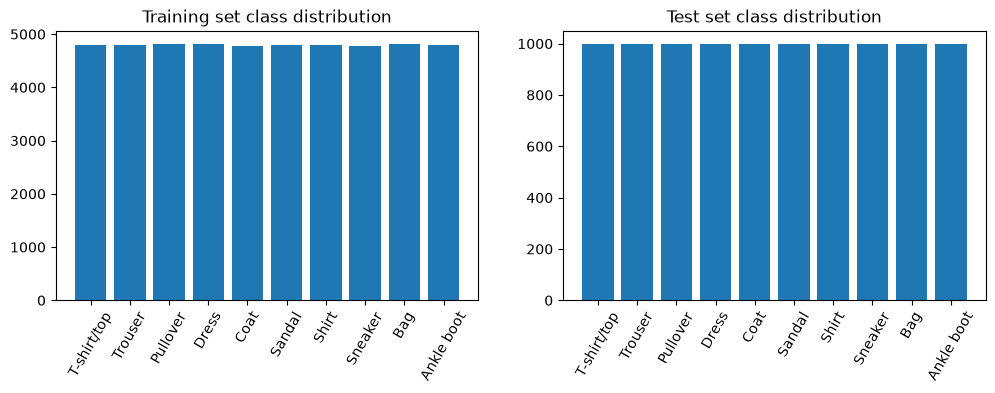

In [35]:
class_names = temp_train.classes
print(class_names)

# ADDED: class distribution plot for the "Datasets" section of the report
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(class_names, np.bincount(y_train, minlength=10))
axes[0].set_title('Training set class distribution')
axes[0].tick_params(axis='x', rotation=60)
axes[1].bar(class_names, np.bincount(y_test, minlength=10))
axes[1].set_title('Test set class distribution')
axes[1].tick_params(axis='x', rotation=60)
plt.show()

#Task 2: Implement a Multilayer Perceptron


In [36]:
# helper functions
def relu (a):
  return np.maximum(0,a)

def relu_grad(a):
  return (a>0).astype(float) # a > 0, slope = 1 otherwise = 0

def softmax(logits):
  exp_logits = np.exp(logits - np.max(logits, axis = 1, keepdims = True))
  return exp_logits / np.sum(exp_logits,  axis = 1, keepdims = True)

def one_hot(y,c):
  return np.eye(c)[y]

def evaluate_acc(true, target) :
  return np.sum(true == target)/ len(true)


# More for Q2
# ADDED: tanh and its gradient
def tanh(a):
  return np.tanh(a)

def tanh_grad(a):
  return 1 - np.tanh(a) ** 2


# ADDED: Leaky-ReLU and its gradient
def leaky_relu(a, slope = 0.01):
  return np.where(a > 0, a, slope * a)

def leaky_relu_grad(a, slope = 0.01):
  return np.where(a > 0, 1.0, slope)   # a > 0, slope = 1 otherwise = 0.01



## MLP Class

In [37]:
class MLP:
  def __init__(self, activation, activation_grad, nhidden_layers, hidden_units,
               input_dim = 784, num_classes = 10,
               l1 = 0.0, l2 = 0.0) :

    self.activation = activation
    self.activation_grad = activation_grad
    assert nhidden_layers == len(hidden_units)
    self.l1 = l1
    self.l2 = l2

    # every layers size
    size = [input_dim] + hidden_units + [num_classes]

    # weight matrix + bias for neighbouring layers

    self.weights = []
    self.biases = []

    for i in range(len(size)-1):
      dim_in = size[i]
      dim_out = size[i+1]

      W = np.random.randn(dim_in, dim_out) * np.sqrt(2/dim_in)
      b = np.zeros(dim_out)

      self.weights.append(W)
      self.biases.append(b)

  def forward(self, X):
    a_list = []
    z_list = [X]

    z = X

    for l in range(len(self.weights)):
      a = np.dot(z, self.weights[l]) + self.biases[l] # inputs * weights
      if l < len(self.weights) - 1 :                  # check if its hidden layer
        z = self.activation(a)
      else:                                           # last layer
        z = softmax(a)
      a_list.append(a)
      z_list.append(z)

    return a_list, z_list

  def backward(self, X, y):
    N = X.shape[0]

    #forward pass
    a_list, z_list = self.forward(X)
    yh = z_list[-1]                     # predicted probabilities

    dW = [None] * len(self.weights)
    db = [None] * len(self.weights)

    dy = yh - y

    for l in reversed(range(len(self.weights))):
      dW[l] = np.dot(z_list[l].T, dy) / N
      dW[l] += self.l2 * self.weights[l] + self.l1 * np.sign(self.weights[l]) #ADDED: l1 and l2 reg
      db[l] = np.sum(dy, axis = 0 ) / N # average error/ unit
      if l > 0:
        dz = np.dot(dy, self.weights[l].T)
        dy = dz * self.activation_grad(a_list[l-1])

    return dW, db





  def fit(self, X, y, lr, epochs, batch_size,
          X_eval = None, y_eval = None):
    N = X.shape[0]
    Y = one_hot(y,10)
    self.train_acc = []
    self.eval_acc = []

    for epoch in range(epochs):
      perm = np.random.permutation(N)
      for start in range (0,N, batch_size):
        i = perm[start:start + batch_size]

        dW, db = self.backward(X[i], Y[i]) # grad of current batch

        for l in range(len(self.weights)):
          self.weights[l] -= lr * dW[l]
          self.biases[l] -= lr * db[l]

      acc = evaluate_acc(y, self.predict(X))
      self.train_acc.append(acc)

      # print(epoch, acc)

      if X_eval is not None:
        self.eval_acc.append(evaluate_acc(y_eval, self.predict(X_eval)))

    return self

  def predict(self, X):
    a_list, z_list = self.forward(X) # predicted class for each input with the highest probability

    return np.argmax(z_list[-1], axis = 1)


In [38]:
# #test
# np.random.seed(0)
# m = MLP( relu , relu_grad, 2, [256,256])
# m.fit(X_train, y_train, lr = 0.01, epochs = 10, batch_size = 64)
# print(evaluate_acc(y_val,m.predict(X_val)))

# Task 3: Run the experiments and report


### Common settings



In [39]:
import time

BATCH_SIZE = 64
EPOCHS = 2 if QUICK_RUN else 20
TUNING_EPOCHS = 2 if QUICK_RUN else 5

if QUICK_RUN:
  X_train, y_train, X_train_raw = X_train[:5000], y_train[:5000], X_train_raw[:5000]
  X_val, y_val, X_val_raw = X_val[:1000], y_val[:1000], X_val_raw[:1000]
  X_test, y_test, X_test_raw = X_test[:1000], y_test[:1000], X_test_raw[:1000]

results = {}   # model name -> {'test_acc', 'time', 'history': {'train_acc': [...], 'eval_acc': [...]}}

### Plotting function


In [40]:
def plot_histories(names, title, eval_name = 'test'):
  # names: model names in `results`. Same colour for one model: train dashed, eval solid.
  plt.figure(figsize = (7, 4))
  for i, name in enumerate(names):
    hist = results[name]['history']
    epochs = np.arange(1, len(hist['train_acc']) + 1)
    plt.plot(epochs, hist['train_acc'], '--', color = f'C{i}', label = f'{name} (train)')
    plt.plot(epochs, hist['eval_acc'], '-', color = f'C{i}', label = f'{name} ({eval_name})')
  plt.xlabel('epoch')
  plt.ylabel('accuracy')
  plt.title(title)
  plt.legend(fontsize = 8)
  plt.grid(alpha = .3)
  plt.show()


### Choosing the learning rate (validation set)


lr = 0.005: validation accuracy per epoch [0.8228 0.8402 0.8544 0.8599 0.8617]
lr = 0.01: validation accuracy per epoch [0.8429 0.8577 0.8651 0.8634 0.8743]
lr = 0.05: validation accuracy per epoch [0.8563 0.8658 0.8783 0.8801 0.8861]
lr = 0.1: validation accuracy per epoch [0.8598 0.8583 0.8868 0.8866 0.8742]


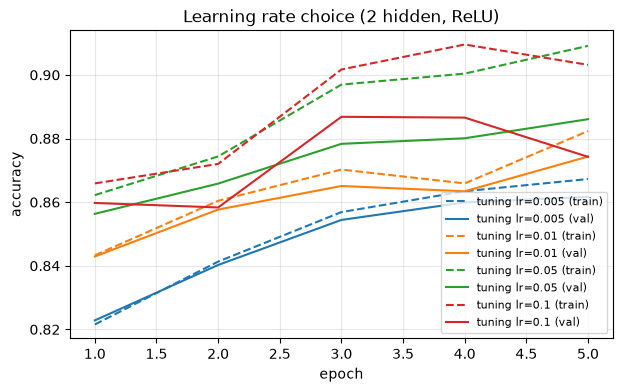

In [41]:
np.random.seed(0)
lr_candidates = [0.005, 0.01, 0.05, 0.1]
for lr in lr_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256])
  model.fit(X_train, y_train, lr, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  results[f'tuning lr={lr}'] = {'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
  print(f'lr = {lr}: validation accuracy per epoch', np.round(model.eval_acc, 4))

plot_histories([f'tuning lr={lr}' for lr in lr_candidates], 'Learning rate choice (2 hidden, ReLU)', eval_name = 'val')

for lr in lr_candidates:
  del results[f'tuning lr={lr}']   # tuning runs are not part of the final results table

### Training function

In [42]:
LEARNING_RATE = 0.05

def run_experiment(name, model, X_tr, y_tr, X_te, y_te, lr = LEARNING_RATE, epochs = EPOCHS):
  print(f'===== {name} =====')
  start = time.time()
  model.fit(X_tr, y_tr, lr, epochs, BATCH_SIZE, X_eval = X_te, y_eval = y_te)
  train_time = time.time() - start
  test_acc = evaluate_acc(y_te, model.predict(X_te))
  print(f'--> test accuracy {test_acc:.4f}, training time {train_time:.1f}s\n')
  results[name] = {'test_acc': test_acc, 'time': train_time,
                   'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
  return model


## MLP SECTION (Q1-Q5)

### Q1: Depth

1. no hidden layer
2. one hidden layer with 256 ReLU units
3. two hidden layers with 256 ReLU units each

===== 0 hidden =====
--> test accuracy 0.8404, training time 3.4s

===== 1 hidden ReLU =====
--> test accuracy 0.8810, training time 35.3s

===== 2 hidden ReLU =====
--> test accuracy 0.8784, training time 51.3s



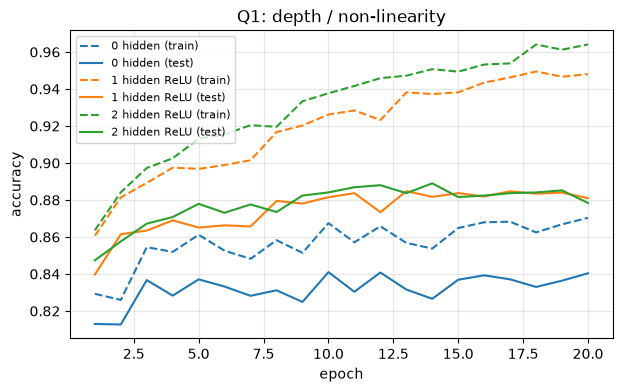

In [43]:
np.random.seed(1)
run_experiment('0 hidden', MLP(relu, relu_grad, 0, []), X_train, y_train, X_test, y_test)
run_experiment('1 hidden ReLU', MLP(relu, relu_grad, 1, [256]), X_train, y_train, X_test, y_test)
run_experiment('2 hidden ReLU', MLP(relu, relu_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)

plot_histories(['0 hidden', '1 hidden ReLU', '2 hidden ReLU'], 'Q1: depth / non-linearity')

### Q2: Activation functions (all 2 hidden layers)
1. ReLU
2. tanh
3. Leaky-ReLU

===== 2 hidden tanh =====
--> test accuracy 0.8779, training time 56.9s

===== 2 hidden LeakyReLU =====
--> test accuracy 0.8883, training time 54.1s



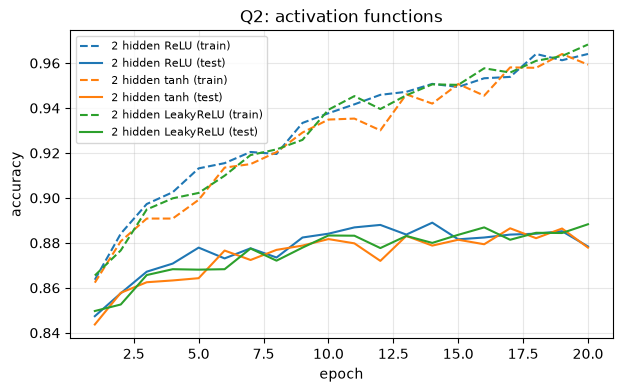

In [44]:
np.random.seed(2)
run_experiment('2 hidden tanh', MLP(tanh, tanh_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)
run_experiment('2 hidden LeakyReLU', MLP(leaky_relu, leaky_relu_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)

plot_histories(['2 hidden ReLU', '2 hidden tanh', '2 hidden LeakyReLU'], 'Q2: activation functions')

### Q3: L1 and L2 regularization

First choose the strength $\lambda$ for each type on the **validation** set, then train the final models.

lambda = 0: validation accuracy L1 0.8858, L2 0.8879
lambda = 1e-05: validation accuracy L1 0.8842, L2 0.8807
lambda = 0.0001: validation accuracy L1 0.8831, L2 0.8904
lambda = 0.001: validation accuracy L1 0.8357, L2 0.8826
lambda = 0.01: validation accuracy L1 0.7544, L2 0.8653
lambda = 0.1: validation accuracy L1 0.0982, L2 0.7563


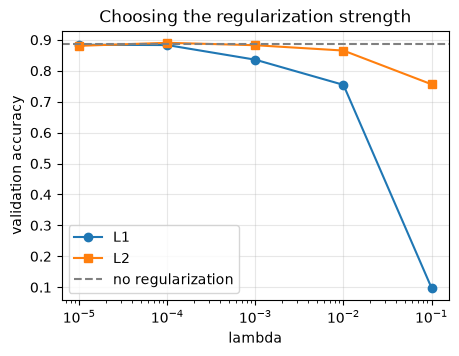

chosen lambda for L1: 1e-05   for L2: 0.0001


In [45]:
# Choose Lambda
np.random.seed(3)
lambda_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
val_acc_l1 = []
val_acc_l2 = []
for lam in lambda_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256], l1 = lam)
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_l1.append(model.eval_acc[-1])

  model = MLP(relu, relu_grad, 2, [256, 256], l2 = lam)
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_l2.append(model.eval_acc[-1])

  print(f'lambda = {lam}: validation accuracy L1 {val_acc_l1[-1]:.4f}, L2 {val_acc_l2[-1]:.4f}')

nonzero = lambda_candidates[1:]

plt.figure(figsize = (5, 3.5))
plt.semilogx(nonzero, val_acc_l1[1:], 'o-', label = 'L1')
plt.semilogx(nonzero, val_acc_l2[1:], 's-', label = 'L2')

plt.axhline(val_acc_l1[0], color = 'gray', linestyle = '--', label = 'no regularization')   # lambda = 0 baseline

plt.xlabel('lambda'); plt.ylabel('validation accuracy'); plt.legend(); plt.grid(alpha = .3)
plt.title('Choosing the regularization strength')
plt.show()

# choose among the nonzero lambdas, so the L1 / L2 models are actually regularized
best_l1 = nonzero[int(np.argmax(val_acc_l1[1:]))]
best_l2 = nonzero[int(np.argmax(val_acc_l2[1:]))]
print('chosen lambda for L1:', best_l1, '  for L2:', best_l2)

===== 2 hidden ReLU + L1 =====
--> test accuracy 0.8911, training time 52.4s

===== 2 hidden ReLU + L2 =====
--> test accuracy 0.8847, training time 50.5s



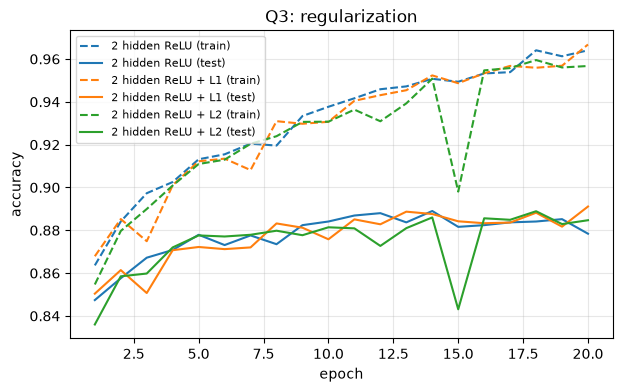

In [46]:
np.random.seed(30)
run_experiment('2 hidden ReLU + L1', MLP(relu, relu_grad, 2, [256, 256], l1 = best_l1), X_train, y_train, X_test, y_test)
run_experiment('2 hidden ReLU + L2', MLP(relu, relu_grad, 2, [256, 256], l2 = best_l2), X_train, y_train, X_test, y_test)

plot_histories(['2 hidden ReLU', '2 hidden ReLU + L1', '2 hidden ReLU + L2'], 'Q3: regularization')

### Q4: Training on unnormalized images

2 hidden layer ReLU MLP on the raw pixel values 0..255 (`X_train_raw` from Task 1), with the same learning rate.


### *Q4 Bonus Test* (Try different learning rates)

The inputs are 255 times larger, so the first-layer pre-activations and gradients are much larger and the same step size
can blow up training. We also try a much smaller learning rate to see whether the step size is the only problem.

===== 2 hidden ReLU, unnormalized =====
--> test accuracy 0.1000, training time 49.3s

===== 2 hidden ReLU, unnormalized, lr=1e-5 =====
--> test accuracy 0.7812, training time 56.6s



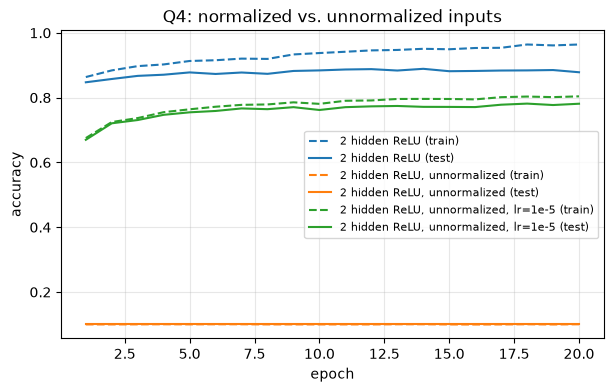

In [47]:
np.random.seed(4)
run_experiment('2 hidden ReLU, unnormalized', MLP(relu, relu_grad, 2, [256, 256]),
               X_train_raw, y_train, X_test_raw, y_test)
run_experiment('2 hidden ReLU, unnormalized, lr=1e-5', MLP(relu, relu_grad, 2, [256, 256]),
               X_train_raw, y_train, X_test_raw, y_test, lr = 1e-5)

plot_histories(['2 hidden ReLU', '2 hidden ReLU, unnormalized', '2 hidden ReLU, unnormalized, lr=1e-5'],
               'Q4: normalized vs. unnormalized inputs')

### Q5: Data augmentation


training set with augmentation: (96000, 784)


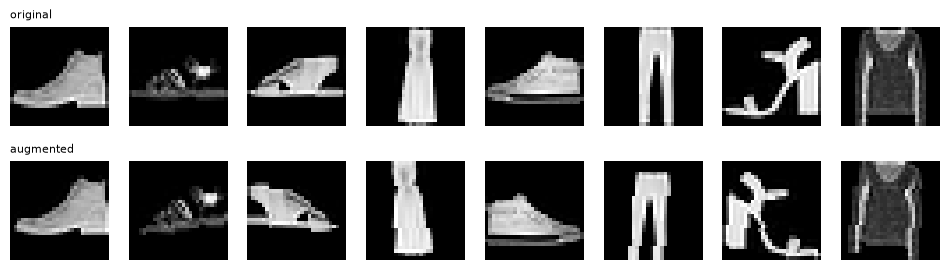

In [48]:
augmentation = [transforms.RandomHorizontalFlip(),
                transforms.RandomAffine(degrees = 10, translate = (0.1, 0.1))]

aug_transform = transforms.Compose(augmentation + [transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
aug_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=aug_transform)

# only select the images already in the training set (don't leak validation set)
aug_data = torch.utils.data.Subset(aug_dataset, train_data.indices[:len(X_train)])
X_aug, y_aug = to_numpy(aug_data)
assert np.all(y_aug == y_train)

X_train_with_aug = np.concatenate([X_train, X_aug])
y_train_with_aug = np.concatenate([y_train, y_aug])
print('training set with augmentation:', X_train_with_aug.shape)

# samples of original image v.s. augmented image
# to show the effect of augmentation
fig, axes = plt.subplots(2, 8, figsize = (12, 3.2))
for i in range(8):
  axes[0, i].imshow(X_train[i].reshape(28, 28), cmap = 'gray'); axes[0, i].axis('off')
  axes[1, i].imshow(X_aug[i].reshape(28, 28), cmap = 'gray'); axes[1, i].axis('off')
axes[0, 0].set_title('original', fontsize = 8, loc = 'left')
axes[1, 0].set_title('augmented', fontsize = 8, loc = 'left')
plt.show()

Re-train MLP from Q3 on that augmented data

===== 2 hidden ReLU + L2 + augmentation =====
--> test accuracy 0.8826, training time 114.2s



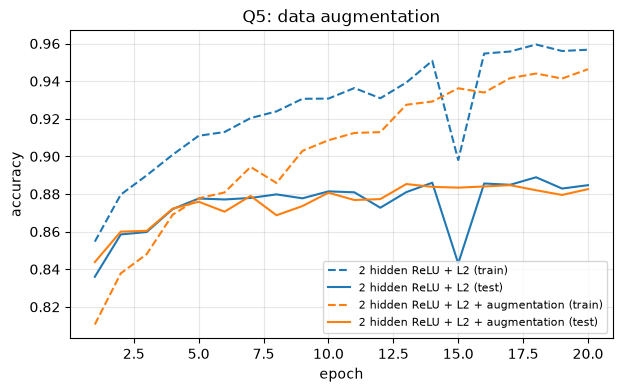

In [49]:
np.random.seed(5)
run_experiment('2 hidden ReLU + L2 + augmentation', MLP(relu, relu_grad, 2, [256, 256], l2 = best_l2),
               X_train_with_aug, y_train_with_aug, X_test, y_test)

plot_histories(['2 hidden ReLU + L2', '2 hidden ReLU + L2 + augmentation'], 'Q5: data augmentation')

# Task 3 Part 2: CNN (Q6-Q9)

## Setup

In [57]:
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision

torch.manual_seed(0)
if torch.cuda.is_available():
  device = torch.device('cuda')
elif torch.backends.mps.is_available():      # Apple Silicon GPU
  device = torch.device('mps')
else:
  device = torch.device('cpu')
print(f'Using device: {device}')

Using device: mps


### Data loader

In [58]:
def make_loaders(train_tf, eval_tf, batch_size = 64):
  # two copies of the training partition: one with the training transform, one with the evaluation transform
  train_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=train_tf)
  eval_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=eval_tf)
  test_full = datasets.FashionMNIST(root="./data", train=False, download=True, transform=eval_tf)

  train_idx = train_data.indices                # same split as Part 1 (Task 1), so the comparison is fair
  val_idx = val_data.indices
  test_idx = list(range(len(test_full)))
  if QUICK_RUN:
    train_idx, val_idx, test_idx = train_idx[:2000], val_idx[:500], test_idx[:500]

  trainloader = DataLoader(torch.utils.data.Subset(train_full, train_idx), batch_size = batch_size, shuffle = True, num_workers = 2)
  # train_idx is already in random order, so its first 10k images are a random sample of the training set
  train_evalloader = DataLoader(torch.utils.data.Subset(eval_full, train_idx[:10000]), batch_size = batch_size, shuffle = False, num_workers = 2)
  valloader = DataLoader(torch.utils.data.Subset(eval_full, val_idx), batch_size = batch_size, shuffle = False, num_workers = 2)
  testloader = DataLoader(torch.utils.data.Subset(test_full, test_idx), batch_size = batch_size, shuffle = False, num_workers = 2)
  return trainloader, train_evalloader, valloader, testloader

trainloader, train_evalloader, valloader, testloader = make_loaders(train_transform, train_transform)   # Task 1 normalization
trainloader_aug, _, _, _ = make_loaders(aug_transform, train_transform)                                 # Q5 augmentation
print('training batches:', len(trainloader), ' validation batches:', len(valloader), ' test batches:', len(testloader))

training batches: 750  validation batches: 188  test batches: 157


### Training and evaluation function

In [59]:
def predict_labels(model, loader):
  model.eval()
  true_labels = []
  predictions = []
  with torch.no_grad():
    for images, labels in loader:
      outputs = model(images.to(device))
      predictions.append(outputs.argmax(dim = 1).cpu().numpy())   # class with the highest score
      true_labels.append(labels.numpy())
  return np.concatenate(true_labels), np.concatenate(predictions)


def evaluate_accuracy(model, loader):
  true_labels, predictions = predict_labels(model, loader)
  return evaluate_acc(true_labels, predictions)   # Part 1 accuracy function


def train_model(model, trainloader, train_evalloader, evalloader, num_epochs = 5, lr = 0.01, testloader = None):
  criterion = nn.CrossEntropyLoss()
  # only parameters with requires_grad=True are trained (matters for the frozen pre-trained model)
  trainable = [p for p in model.parameters() if p.requires_grad]
  optimizer = optim.SGD(trainable, lr = lr, momentum = 0.9)

  history = {'train_acc': [], 'eval_acc': [], 'test_acc': []}
  train_time = 0
  for epoch in range(num_epochs):
    # ===== Training phase =====
    start = time.time()
    model.train()
    for images, labels in trainloader:
      images = images.to(device)
      labels = labels.to(device)

      optimizer.zero_grad()
      outputs = model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()
    train_time += time.time() - start             # only the training phase counts as training time

    # ===== Evaluation phase =====
    history['train_acc'].append(evaluate_accuracy(model, train_evalloader))
    history['eval_acc'].append(evaluate_accuracy(model, evalloader))
    if testloader is not None:
      history['test_acc'].append(evaluate_accuracy(model, testloader))
    print(f'Epoch [{epoch + 1}/{num_epochs}] - train acc {history["train_acc"][-1]:.4f}, '
          f'eval acc {history["eval_acc"][-1]:.4f}, training time so far {train_time:.0f}s')

  history['time'] = train_time
  return history

## Q6: CNN with 2 convolutional layers


In [60]:
class ConvNet(nn.Module):

  def __init__(self, channels = (16, 32)):
    super(ConvNet, self).__init__()
    c1, c2 = channels
    self.conv1 = nn.Conv2d(1, c1, kernel_size = 3, stride = 1, padding = 1)
    self.conv2 = nn.Conv2d(c1, c2, kernel_size = 3, stride = 1, padding = 1)
    self.pool = nn.MaxPool2d(kernel_size = 2, stride = 2)
    self.fc1 = nn.Linear(c2 * 7 * 7, 256)                # two 2x2 poolings: 28 -> 14 -> 7
    self.fc2 = nn.Linear(256, 10)

  def forward(self, x):
    # x: (N, 1, 28, 28)
    x = self.pool(F.relu(self.conv1(x)))   # (N, 16, 14, 14)
    x = self.pool(F.relu(self.conv2(x)))   # (N, 32, 7, 7)
    x = x.view(x.size(0), -1)              # (N, 1568)
    x = F.relu(self.fc1(x))                # (N, 256)
    x = self.fc2(x)                        # (N, 10) scores; CrossEntropyLoss applies the softmax
    return x

print(ConvNet())
print(f'Trainable parameters: {sum(p.numel() for p in ConvNet().parameters()):,}')

ConvNet(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
Trainable parameters: 409,034


### Choosing the CNN learning rate (validation set)

learning rate 0.001
Epoch [1/3] - train acc 0.7773, eval acc 0.7808, training time so far 7s
Epoch [2/3] - train acc 0.8320, eval acc 0.8288, training time so far 12s
Epoch [3/3] - train acc 0.8491, eval acc 0.8444, training time so far 18s
learning rate 0.01
Epoch [1/3] - train acc 0.8718, eval acc 0.8664, training time so far 6s
Epoch [2/3] - train acc 0.8943, eval acc 0.8871, training time so far 11s
Epoch [3/3] - train acc 0.9046, eval acc 0.8962, training time so far 16s
learning rate 0.05
Epoch [1/3] - train acc 0.8891, eval acc 0.8795, training time so far 5s
Epoch [2/3] - train acc 0.9122, eval acc 0.8978, training time so far 11s
Epoch [3/3] - train acc 0.9160, eval acc 0.9008, training time so far 17s


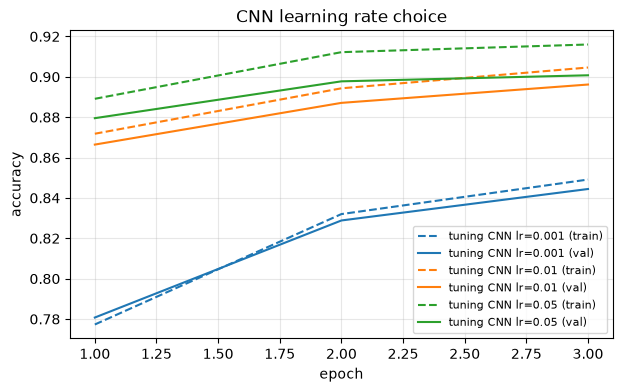

chosen CNN learning rate: 0.05


In [61]:
CNN_TUNING_EPOCHS = 1 if QUICK_RUN else 3

cnn_lr_candidates = [0.001, 0.01, 0.05]
for lr in cnn_lr_candidates:
  print(f'learning rate {lr}')
  torch.manual_seed(0)
  results[f'tuning CNN lr={lr}'] = {'history': train_model(ConvNet().to(device), trainloader, train_evalloader, valloader,
                                                           num_epochs = CNN_TUNING_EPOCHS, lr = lr)}

plot_histories([f'tuning CNN lr={lr}' for lr in cnn_lr_candidates], 'CNN learning rate choice', eval_name = 'val')
CNN_LR = max(cnn_lr_candidates, key = lambda lr: results[f'tuning CNN lr={lr}']['history']['eval_acc'][-1])
for lr in cnn_lr_candidates:
  del results[f'tuning CNN lr={lr}']
print('chosen CNN learning rate:', CNN_LR)

Choose number of filters

filters (8, 16)
Epoch [1/3] - train acc 0.8827, eval acc 0.8748, training time so far 6s
Epoch [2/3] - train acc 0.8680, eval acc 0.8625, training time so far 12s
Epoch [3/3] - train acc 0.9000, eval acc 0.8864, training time so far 16s
filters (16, 32)
Epoch [1/3] - train acc 0.8891, eval acc 0.8795, training time so far 6s
Epoch [2/3] - train acc 0.9122, eval acc 0.8978, training time so far 12s
Epoch [3/3] - train acc 0.9160, eval acc 0.9008, training time so far 18s
filters (32, 64)
Epoch [1/3] - train acc 0.8867, eval acc 0.8819, training time so far 9s
Epoch [2/3] - train acc 0.9072, eval acc 0.8969, training time so far 17s
Epoch [3/3] - train acc 0.9221, eval acc 0.9003, training time so far 25s


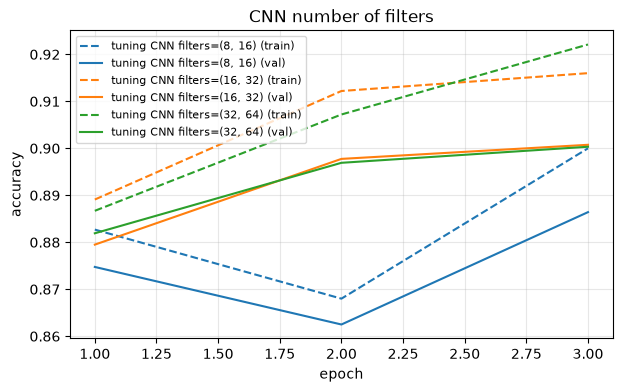

chosen number of filters: (16, 32)


In [62]:
channel_candidates = [(8, 16), (16, 32), (32, 64)]
for ch in channel_candidates:
  print(f'filters {ch}')
  torch.manual_seed(0)
  results[f'tuning CNN filters={ch}'] = {'history': train_model(ConvNet(channels = ch).to(device), trainloader, train_evalloader, valloader,
                                                                num_epochs = CNN_TUNING_EPOCHS, lr = CNN_LR)}

plot_histories([f'tuning CNN filters={ch}' for ch in channel_candidates], 'CNN number of filters', eval_name = 'val')
CNN_CHANNELS = max(channel_candidates, key = lambda ch: results[f'tuning CNN filters={ch}']['history']['eval_acc'][-1])
for ch in channel_candidates:
  del results[f'tuning CNN filters={ch}']
print('chosen number of filters:', CNN_CHANNELS)

Choose the batch size

batch size 32
Epoch [1/3] - train acc 0.8661, eval acc 0.8655, training time so far 9s
Epoch [2/3] - train acc 0.8911, eval acc 0.8779, training time so far 17s
Epoch [3/3] - train acc 0.8942, eval acc 0.8792, training time so far 25s
batch size 64
Epoch [1/3] - train acc 0.8891, eval acc 0.8795, training time so far 5s
Epoch [2/3] - train acc 0.9122, eval acc 0.8978, training time so far 10s
Epoch [3/3] - train acc 0.9160, eval acc 0.9008, training time so far 15s
batch size 128
Epoch [1/3] - train acc 0.8880, eval acc 0.8828, training time so far 5s
Epoch [2/3] - train acc 0.9100, eval acc 0.8976, training time so far 10s
Epoch [3/3] - train acc 0.9161, eval acc 0.9024, training time so far 15s
batch size 256
Epoch [1/3] - train acc 0.8591, eval acc 0.8612, training time so far 5s
Epoch [2/3] - train acc 0.8903, eval acc 0.8824, training time so far 10s
Epoch [3/3] - train acc 0.9099, eval acc 0.9027, training time so far 14s


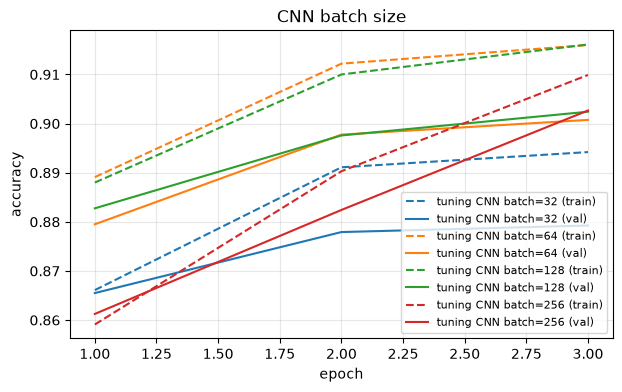

batch size 32: training time 25s
batch size 64: training time 15s
batch size 128: training time 15s
batch size 256: training time 14s
chosen CNN batch size: 256


In [63]:
cnn_batch_candidates = [32, 64, 128, 256]
for bs in cnn_batch_candidates:
  print(f'batch size {bs}')
  bs_trainloader, bs_train_evalloader, bs_valloader, _ = make_loaders(train_transform, train_transform, batch_size = bs)
  torch.manual_seed(0)
  results[f'tuning CNN batch={bs}'] = {'history': train_model(ConvNet(channels = CNN_CHANNELS).to(device), bs_trainloader,
                                                              bs_train_evalloader, bs_valloader,
                                                              num_epochs = CNN_TUNING_EPOCHS, lr = CNN_LR)}

plot_histories([f'tuning CNN batch={bs}' for bs in cnn_batch_candidates], 'CNN batch size', eval_name = 'val')
for bs in cnn_batch_candidates:
  print(f'batch size {bs}: training time {results[f"tuning CNN batch={bs}"]["history"]["time"]:.0f}s')
CNN_BATCH_SIZE = max(cnn_batch_candidates, key = lambda bs: results[f'tuning CNN batch={bs}']['history']['eval_acc'][-1])
for bs in cnn_batch_candidates:
  del results[f'tuning CNN batch={bs}']
print('chosen CNN batch size:', CNN_BATCH_SIZE)

# rebuild the loaders with the chosen batch size
trainloader, train_evalloader, valloader, testloader = make_loaders(train_transform, train_transform, batch_size = CNN_BATCH_SIZE)
trainloader_aug, _, _, _ = make_loaders(aug_transform, train_transform, batch_size = CNN_BATCH_SIZE)

Choose the number of epochs

Epoch [1/20] - train acc 0.8591, eval acc 0.8612, training time so far 5s
Epoch [2/20] - train acc 0.8903, eval acc 0.8824, training time so far 10s
Epoch [3/20] - train acc 0.9099, eval acc 0.9027, training time so far 14s
Epoch [4/20] - train acc 0.9155, eval acc 0.9009, training time so far 18s
Epoch [5/20] - train acc 0.9151, eval acc 0.9020, training time so far 22s
Epoch [6/20] - train acc 0.9248, eval acc 0.9093, training time so far 27s
Epoch [7/20] - train acc 0.9359, eval acc 0.9121, training time so far 31s
Epoch [8/20] - train acc 0.9401, eval acc 0.9149, training time so far 35s
Epoch [9/20] - train acc 0.9499, eval acc 0.9178, training time so far 39s
Epoch [10/20] - train acc 0.9452, eval acc 0.9140, training time so far 43s
Epoch [11/20] - train acc 0.9579, eval acc 0.9153, training time so far 48s
Epoch [12/20] - train acc 0.9612, eval acc 0.9203, training time so far 52s
Epoch [13/20] - train acc 0.9609, eval acc 0.9146, training time so far 56s
Epoch [14/20] - train 

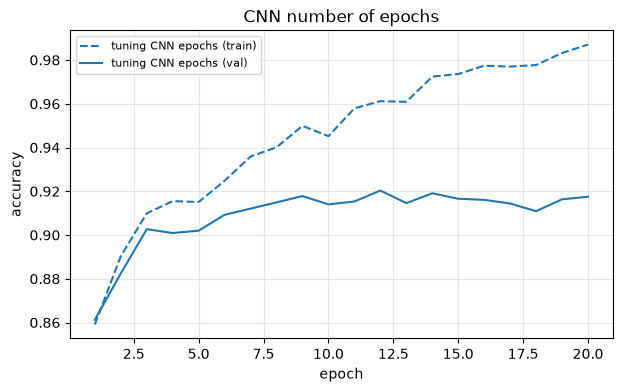

chosen number of CNN epochs: 12


In [64]:
CNN_MAX_EPOCHS = 1 if QUICK_RUN else 20
torch.manual_seed(0)
results['tuning CNN epochs'] = {'history': train_model(ConvNet(channels = CNN_CHANNELS).to(device), trainloader,
                                                       train_evalloader, valloader, num_epochs = CNN_MAX_EPOCHS, lr = CNN_LR)}
plot_histories(['tuning CNN epochs'], 'CNN number of epochs', eval_name = 'val')
CNN_EPOCHS = int(np.argmax(results['tuning CNN epochs']['history']['eval_acc'])) + 1
del results['tuning CNN epochs']
print('chosen number of CNN epochs:', CNN_EPOCHS)

Train CNN

In [65]:
cnn_models = {}   # model name -> trained CNN (used by the extra experiments)

torch.manual_seed(0)
cnn_models['CNN'] = ConvNet(channels = CNN_CHANNELS).to(device)
history = train_model(cnn_models['CNN'], trainloader, train_evalloader, testloader, num_epochs = CNN_EPOCHS, lr = CNN_LR)
results['CNN'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}
print(f"CNN test accuracy {results['CNN']['test_acc']:.4f}, training time {history['time']:.0f}s")

plot_histories(['CNN', best_mlp], 'Q6: CNN vs. best MLP')
print_table([best_mlp, 'CNN'])

Epoch [1/12] - train acc 0.8591, eval acc 0.8435, training time so far 4s
Epoch [2/12] - train acc 0.8903, eval acc 0.8729, training time so far 9s
Epoch [3/12] - train acc 0.9099, eval acc 0.8920, training time so far 14s
Epoch [4/12] - train acc 0.9155, eval acc 0.8919, training time so far 19s
Epoch [5/12] - train acc 0.9151, eval acc 0.8943, training time so far 24s
Epoch [6/12] - train acc 0.9248, eval acc 0.9007, training time so far 29s
Epoch [7/12] - train acc 0.9359, eval acc 0.9044, training time so far 34s
Epoch [8/12] - train acc 0.9401, eval acc 0.9055, training time so far 38s
Epoch [9/12] - train acc 0.9499, eval acc 0.9105, training time so far 43s
Epoch [10/12] - train acc 0.9452, eval acc 0.9047, training time so far 48s
Epoch [11/12] - train acc 0.9579, eval acc 0.9088, training time so far 53s
Epoch [12/12] - train acc 0.9612, eval acc 0.9082, training time so far 58s
CNN test accuracy 0.9082, training time 58s


NameError: name 'best_mlp' is not defined

## Q7: CNN with data augmentation

In [ ]:
torch.manual_seed(0)
cnn_models['CNN + augmentation'] = ConvNet(channels = CNN_CHANNELS).to(device)
history = train_model(cnn_models['CNN + augmentation'], trainloader_aug, train_evalloader, testloader, num_epochs = CNN_EPOCHS, lr = CNN_LR)
results['CNN + augmentation'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}
print(f"CNN + augmentation test accuracy {results['CNN + augmentation']['test_acc']:.4f}, "
      f"training time {history['time']:.0f}s")

plot_histories(['CNN', 'CNN + augmentation'], 'Q6 / Q7: CNN with and without augmentation')
print_table(['CNN', 'CNN + augmentation'])

### Extra 2: a harmful augmentation

Q5 asks when augmentation could hurt. Augmentation only helps if the transformed images still look like
images we could see at test time. FashionMNIST items are always upright, so **vertical flips and large rotations
(±90°)** create images that never appear in the test set (upside-down shoes, sideways trousers), and they turn
some classes into look-alikes of others. We train the same CNN with this augmentation and compare it with the
"good" augmentation from Q5. (We use the CNN because it trains much faster than our NumPy MLP.)

In [ ]:
harmful_augmentation = [transforms.RandomVerticalFlip(), transforms.RandomRotation(90)]
harmful_transform = transforms.Compose(harmful_augmentation + [transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
trainloader_harmful, _, _, _ = make_loaders(harmful_transform, train_transform, batch_size = CNN_BATCH_SIZE)   # validation / test images are NOT changed

# a few training images with the harmful augmentation
images, _ = next(iter(trainloader_harmful))
fig, axes = plt.subplots(1, 8, figsize = (12, 1.8))
for i in range(8):
  axes[i].imshow(images[i, 0], cmap = 'gray'); axes[i].axis('off')
plt.suptitle('harmful augmentation: vertical flip + rotation up to 90 degrees', fontsize = 9)
plt.show()

torch.manual_seed(0)
cnn_models['CNN + harmful augmentation'] = ConvNet(channels = CNN_CHANNELS).to(device)
history = train_model(cnn_models['CNN + harmful augmentation'], trainloader_harmful, train_evalloader, testloader, num_epochs = CNN_EPOCHS, lr = CNN_LR)
results['CNN + harmful augmentation'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

plot_histories(['CNN', 'CNN + augmentation', 'CNN + harmful augmentation'], 'Extra 2: good vs. harmful augmentation')
print_table(['CNN', 'CNN + augmentation', 'CNN + harmful augmentation'])

### Extra 3: where do the best MLP and the best CNN make mistakes?

Confusion matrices (rows = true class, columns = predicted class) and the accuracy of every class.
This shows which classes limit the accuracy and whether the CNN fixes the same mistakes as the MLP.

In [ ]:
def confusion_matrix(true, pred, num_classes = 10):
  cm = np.zeros((num_classes, num_classes), dtype = int)
  for t, p in zip(true, pred):
    cm[t, p] += 1
  return cm

best_cnn = max(['CNN', 'CNN + augmentation'], key = lambda n: results[n]['test_acc'])
mlp_true, mlp_pred = y_test, mlp_models[best_mlp].predict(X_test)
cnn_true, cnn_pred = predict_labels(cnn_models[best_cnn], testloader)

fig, axes = plt.subplots(1, 2, figsize = (14, 6))
for ax, title, true, pred in [(axes[0], f'best MLP: {best_mlp}', mlp_true, mlp_pred),
                              (axes[1], f'best CNN: {best_cnn}', cnn_true, cnn_pred)]:
  cm = confusion_matrix(true, pred)
  ax.imshow(cm, cmap = 'Blues')
  for i in range(10):
    for j in range(10):
      ax.text(j, i, cm[i, j], ha = 'center', va = 'center', fontsize = 7,
              color = 'white' if cm[i, j] > cm.max() / 2 else 'black')
  ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation = 60, fontsize = 8)
  ax.set_yticks(range(10)); ax.set_yticklabels(class_names, fontsize = 8)
  ax.set_xlabel('predicted class'); ax.set_ylabel('true class'); ax.set_title(title)
plt.tight_layout()
plt.show()

# accuracy of every class
mlp_per_class = [np.mean(mlp_pred[mlp_true == c] == c) for c in range(10)]
cnn_per_class = [np.mean(cnn_pred[cnn_true == c] == c) for c in range(10)]
x = np.arange(10)
plt.figure(figsize = (10, 3.5))
plt.bar(x - 0.2, mlp_per_class, 0.4, label = f'best MLP ({best_mlp})')
plt.bar(x + 0.2, cnn_per_class, 0.4, label = f'best CNN ({best_cnn})')
plt.xticks(x, class_names, rotation = 45)
plt.ylim(0.5, 1); plt.ylabel('test accuracy of the class'); plt.legend(fontsize = 8); plt.grid(axis = 'y', alpha = .3)
plt.title('Extra 3: accuracy per class')
plt.show()

# the 5 most common mistakes of the CNN
cm = confusion_matrix(cnn_true, cnn_pred)
np.fill_diagonal(cm, 0)
print('Most common mistakes of the best CNN:')
for k in np.argsort(cm.ravel())[::-1][:5]:
  t, p = divmod(k, 10)
  print(f'  {class_names[t]:12s} predicted as {class_names[p]:12s}: {cm[t, p]} times')

## Q8: Pre-trained ResNet-18 with new fully connected layers

We load a ResNet-18 pre-trained on ImageNet, keep and **freeze** all its convolutional layers, remove its fully
connected layer and add our own. ResNet-18 expects RGB images normalized with the ImageNet mean / std, and is made for
larger images, so each FashionMNIST image is resized to 64×64, copied into 3 channels and normalized with the
ImageNet statistics. The augmentation is the same `augmentation` list as in Q5.

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
PRETRAINED_SIZE = 64

resnet_steps = [transforms.Resize(PRETRAINED_SIZE),
                transforms.Grayscale(num_output_channels = 3),
                transforms.ToTensor(),
                transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
resnet_transform = transforms.Compose(resnet_steps)
resnet_aug_transform = transforms.Compose(augmentation + resnet_steps)   # Q5 augmentation first

pre_trainloader_aug, pre_train_evalloader, pre_valloader, pre_testloader = make_loaders(resnet_aug_transform, resnet_transform)

In [ ]:
class PretrainedResNet(nn.Module):

  def __init__(self, num_fc_layers = 2, hidden_units = 256, num_classes = 10, unfreeze_last_block = False):
    super(PretrainedResNet, self).__init__()
    resnet = torchvision.models.resnet18(weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1)

    # Keep every layer except the last one (resnet.fc, its only fully connected layer).
    # The output of these layers has shape (N, 512, 1, 1).
    self.features = nn.Sequential(*list(resnet.children())[:-1])

    # Freeze the convolutional layers: their weights are not updated.
    for p in self.features.parameters():
      p.requires_grad = False

    # Extra 4 only: also train the last residual block (layer4 = self.features[7]).
    if unfreeze_last_block:
      for p in self.features[7].parameters():
        p.requires_grad = True

    # New fully connected layers: (num_fc_layers - 1) hidden layers with ReLU, then the output layer.
    layers = []
    in_features = 512
    for i in range(num_fc_layers - 1):
      layers.append(nn.Linear(in_features, hidden_units))
      layers.append(nn.ReLU())
      in_features = hidden_units
    layers.append(nn.Linear(in_features, num_classes))
    self.classifier = nn.Sequential(*layers)

  def forward(self, x):
    x = self.features(x)          # (N, 512, 1, 1)
    x = x.view(x.size(0), -1)     # (N, 512)
    return self.classifier(x)     # (N, 10)

  def train(self, mode = True):
    # model.train() would also update the BatchNorm statistics inside the ResNet.
    # The convolutional part is frozen, so we always keep it in evaluation mode
    # (also when layer4 is fine-tuned in Extra 4: we keep the ImageNet BatchNorm statistics).
    super(PretrainedResNet, self).train(mode)
    self.features.eval()
    return self

m = PretrainedResNet(num_fc_layers = 2)
print(m.classifier)
print(f'Trainable parameters: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}'
      f'  (total {sum(p.numel() for p in m.parameters()):,})')

### Choosing the learning rate of the new layers (validation set)

In [ ]:
PRETRAINED_EPOCHS = 1 if QUICK_RUN else 5
PRETRAINED_TUNING_EPOCHS = 1 if QUICK_RUN else 2

pre_lr_candidates = [0.001, 0.01, 0.05]
for lr in pre_lr_candidates:
  print(f'learning rate {lr}')
  torch.manual_seed(0)
  results[f'tuning ResNet lr={lr}'] = {'history': train_model(PretrainedResNet(num_fc_layers = 2).to(device),
                                                              pre_trainloader_aug, pre_train_evalloader, pre_valloader,
                                                              num_epochs = PRETRAINED_TUNING_EPOCHS, lr = lr)}

plot_histories([f'tuning ResNet lr={lr}' for lr in pre_lr_candidates], 'Pre-trained ResNet-18: learning rate choice', eval_name = 'val')
PRETRAINED_LR = max(pre_lr_candidates, key = lambda lr: results[f'tuning ResNet lr={lr}']['history']['eval_acc'][-1])
for lr in pre_lr_candidates:
  del results[f'tuning ResNet lr={lr}']
print('chosen learning rate for the pre-trained model:', PRETRAINED_LR)

### How many fully connected layers? (validation set)

1, 2 or 3 fully connected layers (hidden layers have 256 units). With 1 layer the model is a linear classifier
on top of the frozen ResNet features. The validation curves of this experiment also show whether 5 epochs are enough
(only the small FC head is trained, so it converges in a few epochs). The pre-trained model keeps the course batch
size of 64: every extra ResNet run is expensive, and with a frozen backbone the batch size mostly changes the speed. The number of layers is chosen on the **validation** accuracy;
the test accuracy is recorded at the same time only for the Q10 train / test curves.

In [ ]:
fc_histories = {}
for num_fc in [1, 2, 3]:
  print(f'===== {num_fc} fully connected layer(s) =====')
  torch.manual_seed(0)
  model = PretrainedResNet(num_fc_layers = num_fc).to(device)
  fc_histories[num_fc] = train_model(model, pre_trainloader_aug, pre_train_evalloader, pre_valloader,
                                     num_epochs = PRETRAINED_EPOCHS, lr = PRETRAINED_LR, testloader = pre_testloader)
  results[f'tuning ResNet {num_fc} FC'] = {'history': fc_histories[num_fc]}

plot_histories([f'tuning ResNet {n} FC' for n in [1, 2, 3]], 'Pre-trained ResNet-18: number of FC layers', eval_name = 'val')
for n in [1, 2, 3]:
  del results[f'tuning ResNet {n} FC']

best_num_fc = max([1, 2, 3], key = lambda n: fc_histories[n]['eval_acc'][-1])
print('best number of fully connected layers on the validation set:', best_num_fc)

### Test accuracy of the chosen pre-trained model, compared with the best MLP and the CNN

In [ ]:
best_name = f'ResNet-18 + {best_num_fc} FC'
hist = fc_histories[best_num_fc]
results[best_name] = {'test_acc': hist['test_acc'][-1], 'time': hist['time'],
                      'history': {'train_acc': hist['train_acc'], 'eval_acc': hist['test_acc']}}   # test curve for Q10

print_table([best_mlp, 'CNN', 'CNN + augmentation', best_name])
plot_test_acc([best_mlp, 'CNN', 'CNN + augmentation', best_name], 'Q8: pre-trained model vs. best MLP and CNN')
plot_histories([best_mlp, 'CNN + augmentation', best_name], 'Q8: train / test accuracy')

## Q9: The same pre-trained model on CIFAR-10

CIFAR-10 has 60,000 **colour** 32×32 photos of 10 classes (airplane, car, bird, cat, ...), much closer to the
ImageNet images the ResNet was trained on than grayscale clothes. Same architecture (frozen ResNet-18 + the chosen
number of FC layers), same learning rate, same 64×64 size, ImageNet normalization, and the same Q5 augmentation.

In [ ]:
cifar_steps = [transforms.Resize(PRETRAINED_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
cifar_train = torchvision.datasets.CIFAR10(root = './data', train = True, download = True,
                                           transform = transforms.Compose(augmentation + cifar_steps))
cifar_test = torchvision.datasets.CIFAR10(root = './data', train = False, download = True,
                                          transform = transforms.Compose(cifar_steps))
if QUICK_RUN:
  cifar_train = torch.utils.data.Subset(cifar_train, range(2000))
  cifar_test = torch.utils.data.Subset(cifar_test, range(500))

cifar_trainloader = DataLoader(cifar_train, batch_size = 64, shuffle = True, num_workers = 2)
cifar_testloader = DataLoader(cifar_test, batch_size = 64, shuffle = False, num_workers = 2)

# 10k training images without augmentation, only to measure the training accuracy (same as train_evalloader)
cifar_train_clean = torchvision.datasets.CIFAR10(root = './data', train = True, download = True,
                                                 transform = transforms.Compose(cifar_steps))
cifar_train_evalloader = DataLoader(torch.utils.data.Subset(cifar_train_clean, range(2000 if QUICK_RUN else 10000)),
                                    batch_size = 64, shuffle = False, num_workers = 2)

torch.manual_seed(0)
cifar_model = PretrainedResNet(num_fc_layers = best_num_fc).to(device)
history = train_model(cifar_model, cifar_trainloader, cifar_train_evalloader, cifar_testloader, num_epochs = PRETRAINED_EPOCHS, lr = PRETRAINED_LR)
results[f'{best_name} on CIFAR-10'] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

plot_histories([best_name, f'{best_name} on CIFAR-10'], 'Q9: pre-trained ResNet-18 on two datasets')
print_table([best_name, f'{best_name} on CIFAR-10'])

### Extra 4: frozen vs. fine-tuned ResNet-18 on both datasets

Our explanation for Q9 is that the frozen ImageNet features suit colour photos (CIFAR-10) much better than small
grayscale clothes (FashionMNIST). If that is right, letting the **last residual block (`layer4`)** adapt to the
new data should help FashionMNIST **more** than CIFAR-10. Everything else (FC layers, epochs, augmentation) is the same
as above. Fine-tuning pre-trained weights with a large step can destroy them, so we use at most 0.01 here.

In [ ]:
FINETUNE_LR = min(PRETRAINED_LR, 0.01)
finetuned_name = f'{best_name} fine-tuned'
finetuned_cifar_name = f'{best_name} fine-tuned, CIFAR-10'

torch.manual_seed(0)
finetuned = PretrainedResNet(num_fc_layers = best_num_fc, unfreeze_last_block = True).to(device)
print(f'Trainable parameters: {sum(p.numel() for p in finetuned.parameters() if p.requires_grad):,}')
history = train_model(finetuned, pre_trainloader_aug, pre_train_evalloader, pre_testloader, num_epochs = PRETRAINED_EPOCHS, lr = FINETUNE_LR)
results[finetuned_name] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

torch.manual_seed(0)
finetuned_cifar = PretrainedResNet(num_fc_layers = best_num_fc, unfreeze_last_block = True).to(device)
history = train_model(finetuned_cifar, cifar_trainloader, cifar_train_evalloader, cifar_testloader, num_epochs = PRETRAINED_EPOCHS, lr = FINETUNE_LR)
results[finetuned_cifar_name] = {'test_acc': history['eval_acc'][-1], 'time': history['time'], 'history': history}

print_table([best_name, finetuned_name, f'{best_name} on CIFAR-10', finetuned_cifar_name])
for dataset, frozen, tuned in [('FashionMNIST', best_name, finetuned_name),
                               ('CIFAR-10', f'{best_name} on CIFAR-10', finetuned_cifar_name)]:
  gain = results[tuned]['test_acc'] - results[frozen]['test_acc']
  print(f'{dataset:13s} frozen {results[frozen]["test_acc"]:.4f} -> fine-tuned {results[tuned]["test_acc"]:.4f}  (gain {gain:+.4f})')

plot_histories([best_name, finetuned_name, f'{best_name} on CIFAR-10', finetuned_cifar_name],
               'Extra 4: frozen vs. fine-tuned last block')

# Summary of all models and Q10

Test accuracy and training time of every model. All training times only count the gradient steps (not the
evaluation after each epoch). The MLPs run in NumPy on the **CPU** while the CNNs and the ResNet run in PyTorch on the
**GPU** (`device`), so times are directly comparable within each group, but across the groups part of the difference
comes from the hardware. Then the train / test accuracy per epoch of the MLPs, the CNNs and
the pre-trained models. These curves show after how many epochs each model starts to overfit
(train accuracy keeps rising while test accuracy stops improving).

In [ ]:
names = list(results.keys())
print_table(names)
# all times are measured on the same computer, but on different hardware inside it:
print(f'\nTraining times: MLPs = our NumPy code on the CPU, CNNs / ResNet = PyTorch on {device}.')
print('So compare times within each group; across the groups part of the difference is CPU vs. GPU.')
plot_test_acc(names, 'Test accuracy of all models')

In [ ]:
# Q10: train / test accuracy per epoch
plot_histories(['0 hidden', '1 hidden ReLU', '2 hidden ReLU', '2 hidden tanh', '2 hidden LeakyReLU'], 'Q10: MLPs (depth and activation)')
plot_histories(['2 hidden ReLU', '2 hidden ReLU + L1', '2 hidden ReLU + L2', '2 hidden ReLU + L2 + augmentation'],
               'Q10: MLPs (regularization and augmentation)')
plot_histories(['CNN', 'CNN + augmentation', 'CNN + harmful augmentation'], 'Q10: CNNs')
plot_histories([best_name, f'{best_name} on CIFAR-10', finetuned_name, finetuned_cifar_name], 'Q10: pre-trained ResNet-18')